In [1]:
import os , kagglehub, kaggle
from dotenv import load_dotenv


load_dotenv()
kaggle.api.authenticate()
print("Authenticated successfully!")

Authenticated successfully!


# NOTE : The same notebook is done in google colab to make it more faster with cloud harware. 

In [2]:
curr_dir = os.getcwd()
print(curr_dir)
# Download latest version
path = kagglehub.dataset_download("salader/dogsvscats", output_dir = f'{curr_dir}/Dataset/cat-vs-dog')


print("Path to dataset files:", path)

d:\Notes of CampusX\DL with CampusX


In [3]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Flatten
from keras.applications.vgg16 import VGG16

In [4]:
conv_base = VGG16(
    weights='imagenet',
    include_top = False,
    input_shape=(150,150,3)
)

In [5]:
model = Sequential()

model.add(conv_base)
model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [6]:
conv_base.trainable = False

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img

In [8]:
batch_size = 32

train_datagen = ImageDataGenerator(
        rescale=1./255,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
        fr'{curr_dir}\Dataset\cat-vs-dog\train',
        target_size=(150, 150),
        batch_size=batch_size,
        class_mode='binary') 

validation_generator = test_datagen.flow_from_directory(
        fr'{curr_dir}\Dataset\cat-vs-dog\test',
        target_size=(150, 150),
        batch_size=batch_size,
        class_mode='binary')

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [9]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [10]:
history = model.fit_generator(
        train_generator,
        epochs=10,
        validation_data=validation_generator)

Epoch 1/10


C:\Users\Nakes\AppData\Local\Temp\ipykernel_25228\4146946750.py:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history = model.fit_generator(


625/625 [==============================] - 86s 129ms/step - loss: 0.3090 - accuracy: 0.8686 - val_loss: 0.2223 - val_accuracy: 0.9062
Epoch 2/10
625/625 [==============================] - 77s 123ms/step - loss: 0.2381 - accuracy: 0.8981 - val_loss: 0.2226 - val_accuracy: 0.9056
Epoch 3/10
625/625 [==============================] - 76s 122ms/step - loss: 0.2190 - accuracy: 0.9069 - val_loss: 0.2017 - val_accuracy: 0.9154
Epoch 4/10
625/625 [==============================] - 87s 139ms/step - loss: 0.2119 - accuracy: 0.9088 - val_loss: 0.1984 - val_accuracy: 0.9150
Epoch 5/10
625/625 [==============================] - 85s 136ms/step - loss: 0.2019 - accuracy: 0.9147 - val_loss: 0.1969 - val_accuracy: 0.9178
Epoch 6/10
625/625 [==============================] - 85s 136ms/step - loss: 0.1928 - accuracy: 0.9178 - val_loss: 0.1881 - val_accuracy: 0.9230
Epoch 7/10
625/625 [==============================] - 84s 135ms/step - loss: 0.1792 - accuracy: 0.9237 - val_loss: 0.1960 - val_accuracy: 0.9

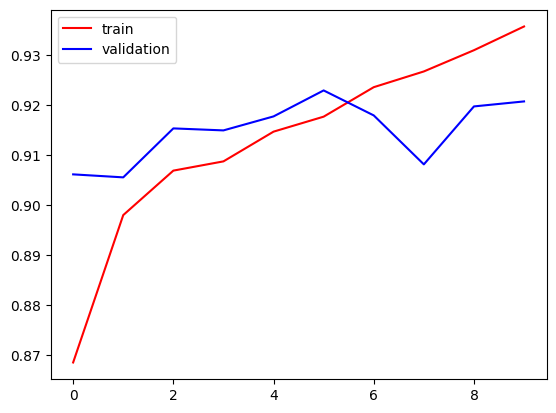

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

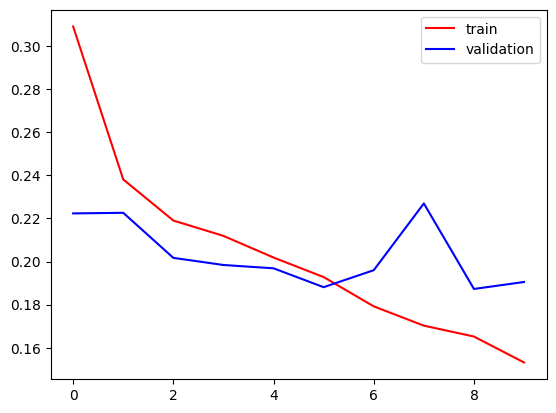

In [12]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

## With data Augmentation

In [14]:
batch_size = 32

train_datagen = ImageDataGenerator(
        rescale=1./255,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
        fr'{curr_dir}\Dataset\cat-vs-dog\train',
        target_size=(150, 150),
        batch_size=batch_size,
        class_mode='binary') 

validation_generator = test_datagen.flow_from_directory(
        fr'{curr_dir}\Dataset\cat-vs-dog\test',
        target_size=(150, 150),
        batch_size=batch_size,
        class_mode='binary')

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [15]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [16]:
history2 = model.fit_generator(
        train_generator,
        epochs=10,
        validation_data=validation_generator)

Epoch 1/10


C:\Users\Nakes\AppData\Local\Temp\ipykernel_25228\1458168773.py:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history2 = model.fit_generator(


625/625 [==============================] - 93s 148ms/step - loss: 0.1500 - accuracy: 0.9374 - val_loss: 0.1908 - val_accuracy: 0.9176
Epoch 2/10
625/625 [==============================] - 112s 179ms/step - loss: 0.1430 - accuracy: 0.9407 - val_loss: 0.1940 - val_accuracy: 0.9224
Epoch 3/10
625/625 [==============================] - 108s 173ms/step - loss: 0.1325 - accuracy: 0.9465 - val_loss: 0.2314 - val_accuracy: 0.9114
Epoch 4/10
625/625 [==============================] - 89s 143ms/step - loss: 0.1252 - accuracy: 0.9485 - val_loss: 0.2141 - val_accuracy: 0.9200
Epoch 5/10
625/625 [==============================] - 79s 126ms/step - loss: 0.1233 - accuracy: 0.9505 - val_loss: 0.2113 - val_accuracy: 0.9168
Epoch 6/10
625/625 [==============================] - 95s 152ms/step - loss: 0.1146 - accuracy: 0.9535 - val_loss: 0.2132 - val_accuracy: 0.9168
Epoch 7/10
625/625 [==============================] - 80s 128ms/step - loss: 0.1126 - accuracy: 0.9550 - val_loss: 0.2043 - val_accuracy: 0

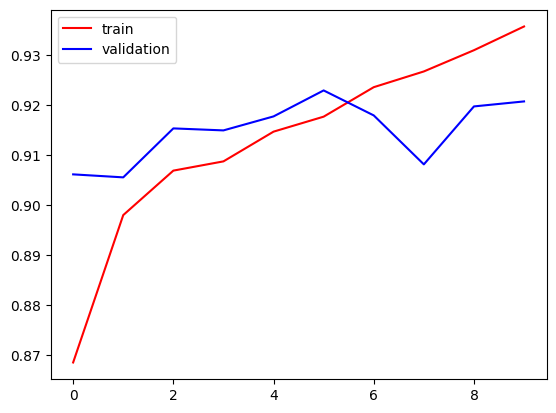

In [18]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

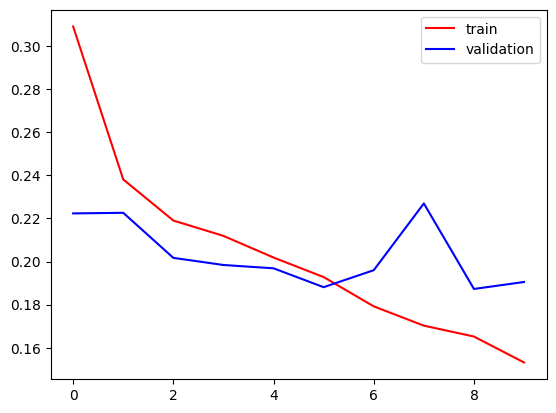

In [19]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

# With Fine Tuning
## --> Trains the Last few Colvolution layers

In [20]:
conv_base = VGG16(
    weights='imagenet',
    include_top = False,
    input_shape=(150,150,3)
)

In [21]:
conv_base.trainable = True

set_trainable = False

for layer in conv_base.layers:
  if layer.name == 'block5_conv1':
    set_trainable = True
  if set_trainable:
    layer.trainable = True
  else:
    layer.trainable = False

for layer in conv_base.layers:
  print(layer.name,layer.trainable)

input_2 False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [22]:
conv_base.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 150, 150, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 150, 150, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 150, 150, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 75, 75, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 75, 75, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 75, 75, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 37, 37, 128)       0     

In [23]:
model = Sequential()

model.add(conv_base)
model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [24]:
# generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = fr'{curr_dir}\Dataset\cat-vs-dog\train',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(150,150)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = fr'{curr_dir}\Dataset\cat-vs-dog\test',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(150,150)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [25]:
# Normalize
def process(image,label):
    image = tensorflow.cast(image/255. ,tensorflow.float32)
    return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [26]:
model.compile(
    optimizer=keras.optimizers.RMSprop(lr=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
  )

d:\Notes of CampusX\DL with CampusX\.dlenv\lib\site-packages\keras\optimizers\optimizer_v2\rmsprop.py:140: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super().__init__(name, **kwargs)


In [27]:
history = model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10
625/625 [==============================] - 67s 96ms/step - loss: 0.2370 - accuracy: 0.9011 - val_loss: 0.1686 - val_accuracy: 0.9276
Epoch 2/10
625/625 [==============================] - 62s 98ms/step - loss: 0.1322 - accuracy: 0.9482 - val_loss: 0.1374 - val_accuracy: 0.9440
Epoch 3/10
625/625 [==============================] - 59s 94ms/step - loss: 0.0915 - accuracy: 0.9657 - val_loss: 0.1265 - val_accuracy: 0.9490
Epoch 4/10
625/625 [==============================] - 81s 130ms/step - loss: 0.0626 - accuracy: 0.9794 - val_loss: 0.1290 - val_accuracy: 0.9502
Epoch 5/10
625/625 [==============================] - 89s 142ms/step - loss: 0.0407 - accuracy: 0.9887 - val_loss: 0.1310 - val_accuracy: 0.9504
Epoch 6/10
625/625 [==============================] - 83s 134ms/step - loss: 0.0266 - accuracy: 0.9930 - val_loss: 0.1315 - val_accuracy: 0.9534
Epoch 7/10
625/625 [==============================] - 67s 108ms/step - loss: 0.0167 - accuracy: 0.9957 - val_loss: 0.1469 - val_accur

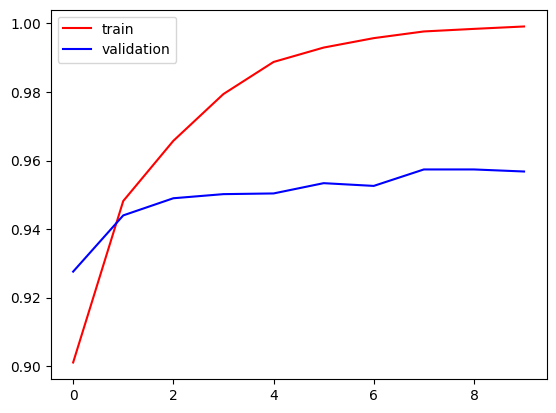

In [28]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

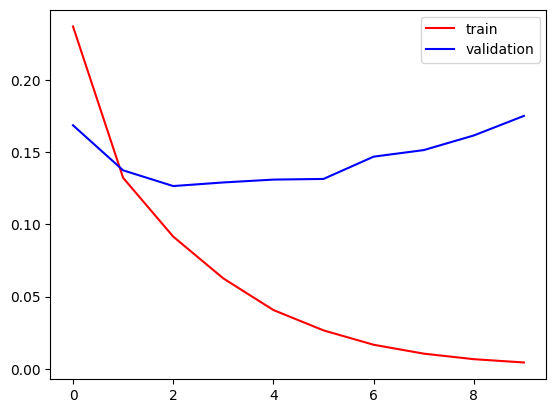

In [29]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()